# 🐶 Dog Object Detection with YOLO (Ultralytics YOLOv8 / YOLO11)

สมุดบันทึก (Jupyter Notebook) นี้จัดทำขึ้นสำหรับการทำ **Object Detection (ตรวจจับตำแหน่งและตีกรอบ Bounding Box สำหรับสุนัข)**
- **โมเดลที่ใช้:** YOLOv8 / YOLO11 (Pre-trained บน COCO Dataset ซึ่งมี Class ID 16 คือ `dog` พร้อมใช้งานทันทีโดยไม่ต้องเทรนใหม่)
- **เนื้อหาใน Notebook:**
  1. ติดตั้งไลบรารีและโหลดโมเดลตรวจจับ
  2. เชื่อมต่อรูปภาพสุนัขจาก Dataset โฟลเดอร์ `My First Project.v1i.folder`
  3. ตรวจจับตำแหน่งสุนัขบนภาพเดี่ยว (Single Image Inference) และพล็อต Bounding Box
  4. ทดสอบตรวจจับสุนัขหลายสายพันธุ์พร้อมกัน (Beagle, Boxer, Chihuahua, Pomeranian ฯลฯ)
  5. ครอปเฉพาะตัวสุนัข (Cropping Bounding Box) และบันทึกลงโฟลเดอร์
  6. สคริปต์ตรวจจับสุนัขแบบ Real-time ผ่านกล้อง Webcam
  7. คำแนะนำและโค้ดสำหรับการ Train โมเดล Custom Dog Detection


In [2]:
# ติดตั้งไลบรารีที่จำเป็น (รันเซลล์นี้เพียงครั้งเดียว)
!pip install ultralytics opencv-python matplotlib pillow



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: C:\Users\perth\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


### 1. นำเข้าไลบรารีและโหลดโมเดล YOLOv8 Pre-trained

In [1]:
import os
import glob
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

# โหลดโมเดล YOLOv8 Nano (รวดเร็ว น้ำหนักเบา และแม่นยำ)
# โมเดลนี้ถูก Train บน COCO Dataset ซึ่งมีคลาส 'dog' อยู่ที่ ID 16
model = YOLO('yolov8n.pt')

print("✅ โหลดโมเดล YOLOv8 สำเร็จ!")
print(f"Class ID 16 ใน COCO คือ: '{model.names[16]}'")


✅ โหลดโมเดล YOLOv8 สำเร็จ!
Class ID 16 ใน COCO คือ: 'dog'


### 2. กำหนด Path ของชุดข้อมูลและตรวจสอบไฟล์ภาพ

In [2]:
# กำหนด Path ของโฟลเดอร์ Dataset
dataset_dir = r"C:\Users\perth\Downloads\My First Project.v1i.folder"
test_dir = os.path.join(dataset_dir, "test")

# ค้นหาภาพสุนัขจากโฟลเดอร์ย่อยใน test
sample_images = glob.glob(os.path.join(test_dir, "*", "*.jpg"))
print(f"จำนวนรูปภาพทั้งหมดในโฟลเดอร์ test: {len(sample_images)} รูป")

# แสดงตัวอย่าง 3 ภาพแรก
for p in sample_images[:3]:
    print("-", p)


จำนวนรูปภาพทั้งหมดในโฟลเดอร์ test: 499 รูป
- C:\Users\perth\Downloads\My First Project.v1i.folder\test\Beagle\Beagle_0001_jpg.rf.489b884bdd7a27e2cb43d6810a9f505e.jpg
- C:\Users\perth\Downloads\My First Project.v1i.folder\test\Beagle\Beagle_0006_jpg.rf.6707792e9391564466b4428f3291f355.jpg
- C:\Users\perth\Downloads\My First Project.v1i.folder\test\Beagle\Beagle_0010_jpg.rf.3a73e62c2eefa491798b79e815a0da87.jpg


### 3. ตรวจจับตำแหน่งสุนัข (Single Image Inference)
ใช้พารามิเตอร์ `classes=[16]` เพื่อกรองให้โมเดลตรวจจับเฉพาะ **สุนัข (Dog)** เท่านั้น

กำลังตรวจจับภาพ: C:\Users\perth\Downloads\My First Project.v1i.folder\test\Beagle\Beagle_0001_jpg.rf.489b884bdd7a27e2cb43d6810a9f505e.jpg

image 1/1 C:\Users\perth\Downloads\My First Project.v1i.folder\test\Beagle\Beagle_0001_jpg.rf.489b884bdd7a27e2cb43d6810a9f505e.jpg: 640x640 1 dog, 131.8ms
Speed: 6.0ms preprocess, 131.8ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 640)


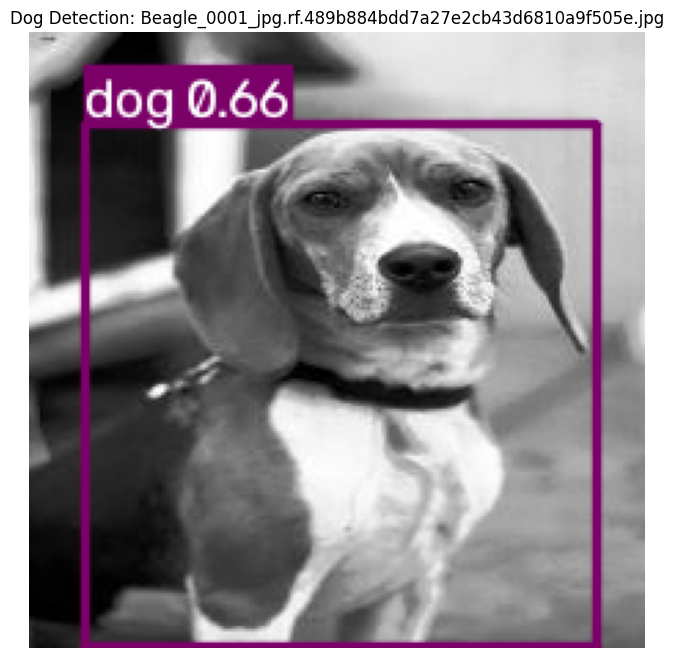

พบสุนัขทั้งหมด: 1 ตัวในภาพนี้
[1] คลาส: dog | ความเชื่อมั่น: 65.68% | Box (xyxy): [20.7, 33.7, 206.2, 223.8]


In [3]:
# เลือกภาพทดสอบ 1 ภาพ
sample_img_path = sample_images[0]
print(f"กำลังตรวจจับภาพ: {sample_img_path}")

# รัน Object Detection
results = model.predict(
    source=sample_img_path,
    classes=[16],  # 16 = dog
    conf=0.25,     # ค่าเกณฑ์ความเชื่อมั่นขั้นต่ำ 25%
    save=False
)

result = results[0]

# แปลงผลลัพธ์ BGR เป็น RGB เพื่อนำมาพล็อตด้วย Matplotlib
res_bgr = result.plot()
res_rgb = cv2.cvtColor(res_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(res_rgb)
plt.title(f"Dog Detection: {os.path.basename(sample_img_path)}")
plt.axis("off")
plt.show()

# แสดงพิกัดและค่าความเชื่อมั่นของ Bounding Box ที่ตรวจพบ
print(f"พบสุนัขทั้งหมด: {len(result.boxes)} ตัวในภาพนี้")
for idx, box in enumerate(result.boxes):
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    conf = float(box.conf[0])
    cls_id = int(box.cls[0])
    label = model.names[cls_id]
    print(f"[{idx+1}] คลาส: {label} | ความเชื่อมั่น: {conf:.2%} | Box (xyxy): [{x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f}]")


### 4. ตรวจจับและเปรียบเทียบผลลัพธ์หลายสายพันธุ์ (Batch Test)

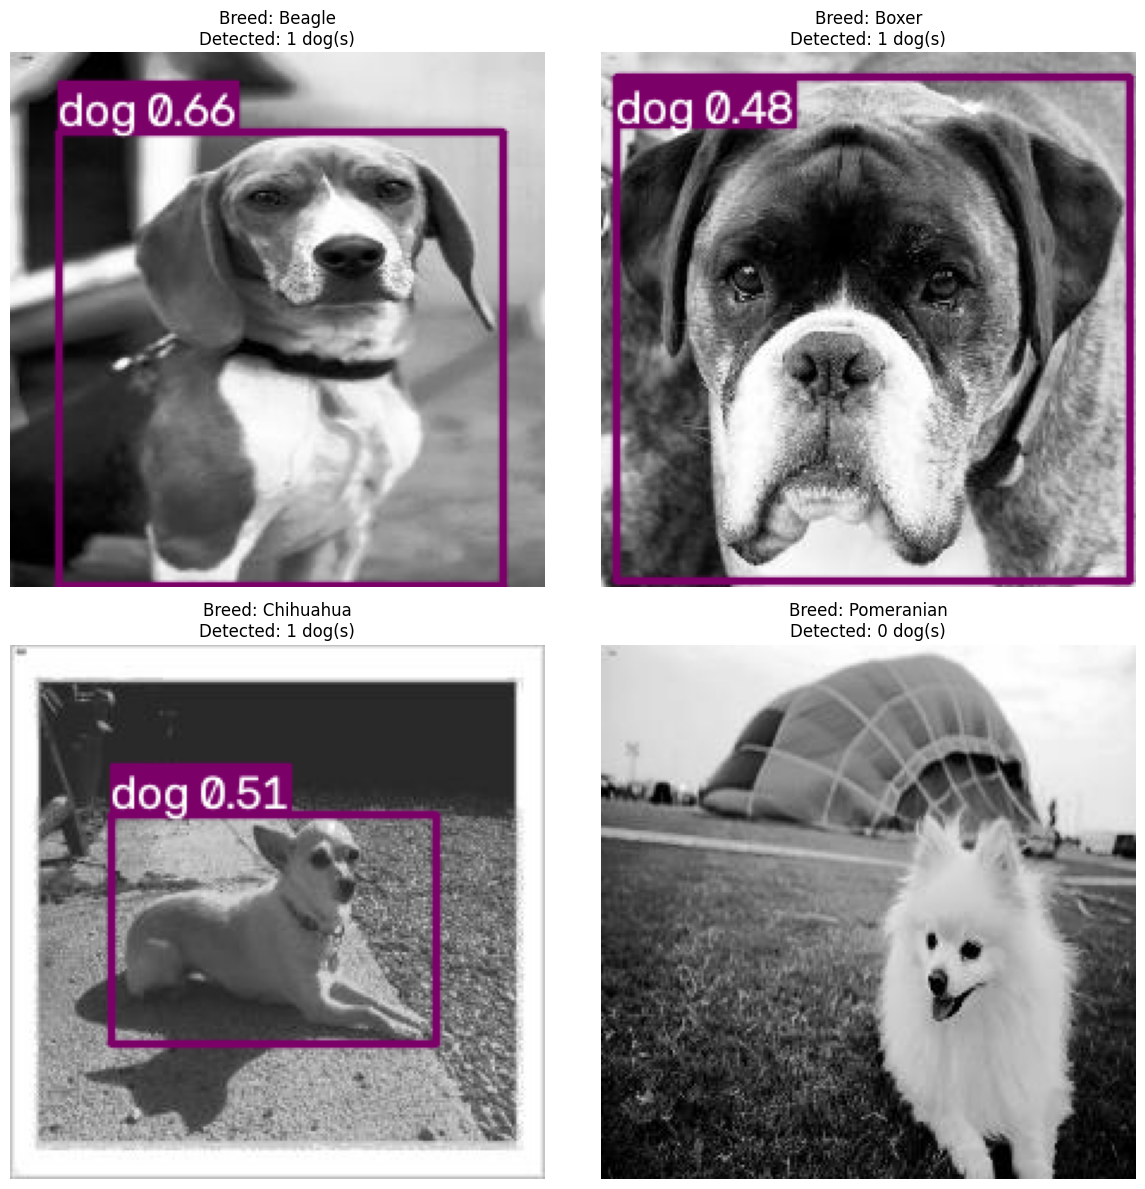

In [4]:
# ทดสอบตรวจจับสุนัขจาก 4 สายพันธุ์ที่แตกต่างกัน
breeds = ['Beagle', 'Boxer', 'Chihuahua', 'Pomeranian']
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()

for idx, breed in enumerate(breeds):
    breed_images = glob.glob(os.path.join(test_dir, breed, "*.jpg"))
    if not breed_images:
        continue
    img_path = breed_images[0]
    
    # Predict
    res = model.predict(source=img_path, classes=[16], conf=0.25, verbose=False)[0]
    res_rgb = cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)
    
    axes[idx].imshow(res_rgb)
    axes[idx].set_title(f"Breed: {breed}\nDetected: {len(res.boxes)} dog(s)", fontsize=12)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()


### 5. ครอปเฉพาะตัวสุนัข (Cropping Bounding Box) และบันทึกไฟล์

กำลังตัดภาพสุนัขจาก: Beagle_0001_jpg.rf.489b884bdd7a27e2cb43d6810a9f505e.jpg
✅ บันทึกภาพครอปที่: C:\Users\perth\Downloads\My First Project.v1i.folder\detected_dog_crops\dog_crop_1.jpg


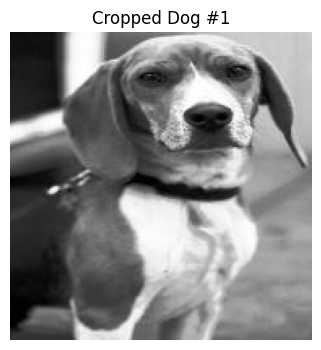

In [5]:
# สร้างโฟลเดอร์สำหรับเก็บภาพครอปสุนัข
output_dir = os.path.join(dataset_dir, "detected_dog_crops")
os.makedirs(output_dir, exist_ok=True)

img_bgr = cv2.imread(sample_img_path)
h, w, _ = img_bgr.shape

print(f"กำลังตัดภาพสุนัขจาก: {os.path.basename(sample_img_path)}")
for i, box in enumerate(result.boxes):
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)
    
    crop = img_bgr[y1:y2, x1:x2]
    crop_path = os.path.join(output_dir, f"dog_crop_{i+1}.jpg")
    cv2.imwrite(crop_path, crop)
    print(f"✅ บันทึกภาพครอปที่: {crop_path}")
    
    plt.figure(figsize=(4, 4))
    plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    plt.title(f"Cropped Dog #{i+1}")
    plt.axis("off")
    plt.show()


### 6. ตรวจจับสุนัขแบบ Real-time ผ่านกล้อง Webcam
*(กดปุ่ม `q` บนคีย์บอร์ดที่หน้าต่างแสดงผลเพื่อหยุดการทำงาน)*

In [ ]:
from IPython.display import display, clear_output
import PIL.Image
import io

def run_webcam_detection(use_popup_window=False, max_frames=200):
    """
    ตรวจจับสุนัขแบบ Real-Time จากกล้อง Webcam
    - use_popup_window=False : แสดงภาพสดใน Notebook โดยตรง (แนะนำสำหรับ Jupyter/VS Code)
    - use_popup_window=True  : เปิดหน้าต่าง Pop-up ของ Windows (กด 'q' เพื่อปิด)
    """
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("❌ ไม่สามารถเปิดกล้อง Webcam ได้ (กรุณาตรวจสอบว่ามีกล้องเชื่อมต่ออยู่ หรือปิดแอปอื่นที่กำลังใช้กล้อง)")
        return
        
    print("🎥 เริ่มตรวจจับสุนัขผ่านกล้อง Webcam...")
    
    if use_popup_window:
        print("💡 กำลังแสดงผลผ่านหน้าต่าง Pop-up (กด 'q' ที่หน้าต่างเพื่อหยุด)")
        while True:
            ret, frame = cap.read()
            if not ret or frame is None:
                break
                
            results = model.predict(frame, classes=[16], conf=0.35, verbose=False)
            annotated_frame = results[0].plot()
            
            cv2.imshow("Dog Object Detection (Press q to exit)", annotated_frame)
            if cv2.waitKey(1) & 0xFF == ord('q'):
                break
        cv2.destroyAllWindows()
    else:
        print("💡 แสดงภาพสดใน Notebook (หยุดอัตโนมัติเมื่อครบกำหนด หรือกดปุ่ม Stop/Interrupt Kernel)")
        try:
            for _ in range(max_frames):
                ret, frame = cap.read()
                if not ret or frame is None:
                    break
                    
                results = model.predict(frame, classes=[16], conf=0.35, verbose=False)
                annotated_frame = results[0].plot()
                
                # แปลง BGR เป็น RGB และแสดงใน Notebook cell
                rgb_frame = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)
                pil_img = PIL.Image.fromarray(rgb_frame)
                
                clear_output(wait=True)
                display(pil_img)
        except KeyboardInterrupt:
            print("⏹️ หยุดการทำงานเรียบร้อยแล้ว")
            
    cap.release()
    print("✅ ปิดกล้อง Webcam เรียบร้อยแล้ว")

# เรียกใช้งาน:
# แสดงผลสดในหน้าต่าง Notebook:
# run_webcam_detection(use_popup_window=False)

# หรือหากต้องการให้เด้งเป็นหน้าต่างแยก ให้เปลี่ยนเป็น:
run_webcam_detection(use_popup_window=True)


### 7. ข้อมูลเพิ่มเติม: การ Train โมเดล Custom Dog Detection
> **หมายเหตุเกี่ยวกับชุดข้อมูล:**
> - โฟลเดอร์ `My First Project.v1i.folder` ในปัจจุบันเป็นรูปแบบ **Image Classification** (แยกรูปตามโฟลเดอร์สายพันธุ์ ไม่มีไฟล์พิกัด Bounding Box)
> - โมเดล YOLO ใน Notebook นี้สามารถตรวจจับสุนัขได้ทันทีด้วย Pre-trained COCO Weights
> - หากในอนาคตต้องการ Train ให้โมเดลระบุ Bounding Box พร้อมชื่อสายพันธุ์เฉพาะ (Custom Object Detection) ท่านสามารถ Export Dataset จาก **Roboflow** อีกครั้งในรูปแบบ **YOLOv8** แล้วรันโค้ดด้านล่างนี้ได้เลยครับ:

In [6]:
# ตัวอย่างโค้ดเมื่อมี Dataset ที่มีพิกัด Bounding Box (YOLO Object Detection format):

from ultralytics import YOLO

# 1. โหลด Base Detection Model
custom_model = YOLO('yolov8n.pt')

# 2. ทำการ Fine-tune ด้วย dataset ของเรา
custom_model.train(
    data=r'C:\Users\perth\Downloads\My First Project.v1i.folder\data.yaml',
    epochs=50,
    imgsz=640,
    batch=16,
    name='dog_breed_detection'
)

# 3. โหลดโมเดลที่ดีที่สุดมาใช้งาน
best_model = YOLO('runs/detect/dog_breed_detection/weights/best.pt')
print("💡 โค้ดตัวอย่างสำหรับการ Train Custom Object Detection พร้อมใช้งานครับ")


Ultralytics 8.4.202  Python-3.12.1 torch-2.15.0+cpu CPU (AMD Ryzen 7 7435HS)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\perth\Downloads\My First Project.v1i.folder\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=dog_breed_detection, nbs=64, nms=N

ValueError: [34m[1mtrain: [0mNo labels found in C:\Users\perth\Downloads\My First Project.v1i.folder\train\Beagle.cache. See https://docs.ultralytics.com/datasets for dataset formatting guidance.